# LDP nos logits — privacidade e utilidade

In [ ]:
from pathlib import Path
import sys
root=Path.cwd().resolve()
while not (root/'requirements.txt').exists() and root!=root.parent: root=root.parent
sys.path.insert(0,str(root))

## 1. Gráfico de síntese

### Síntese do estudo completo — 504 configurações

Uma figura reúne as duas medidas de utilidade, com os pesos 72,73%/27,27%. Cada ponto usa o C com menor MAE para esse mecanismo, representação e ε (200 sorteios por mensagem, três mensagens históricas). **C pode mudar entre pontos**: são resultados exploratórios selecionados nos mesmos logits, não uma comparação com clipping fixo.

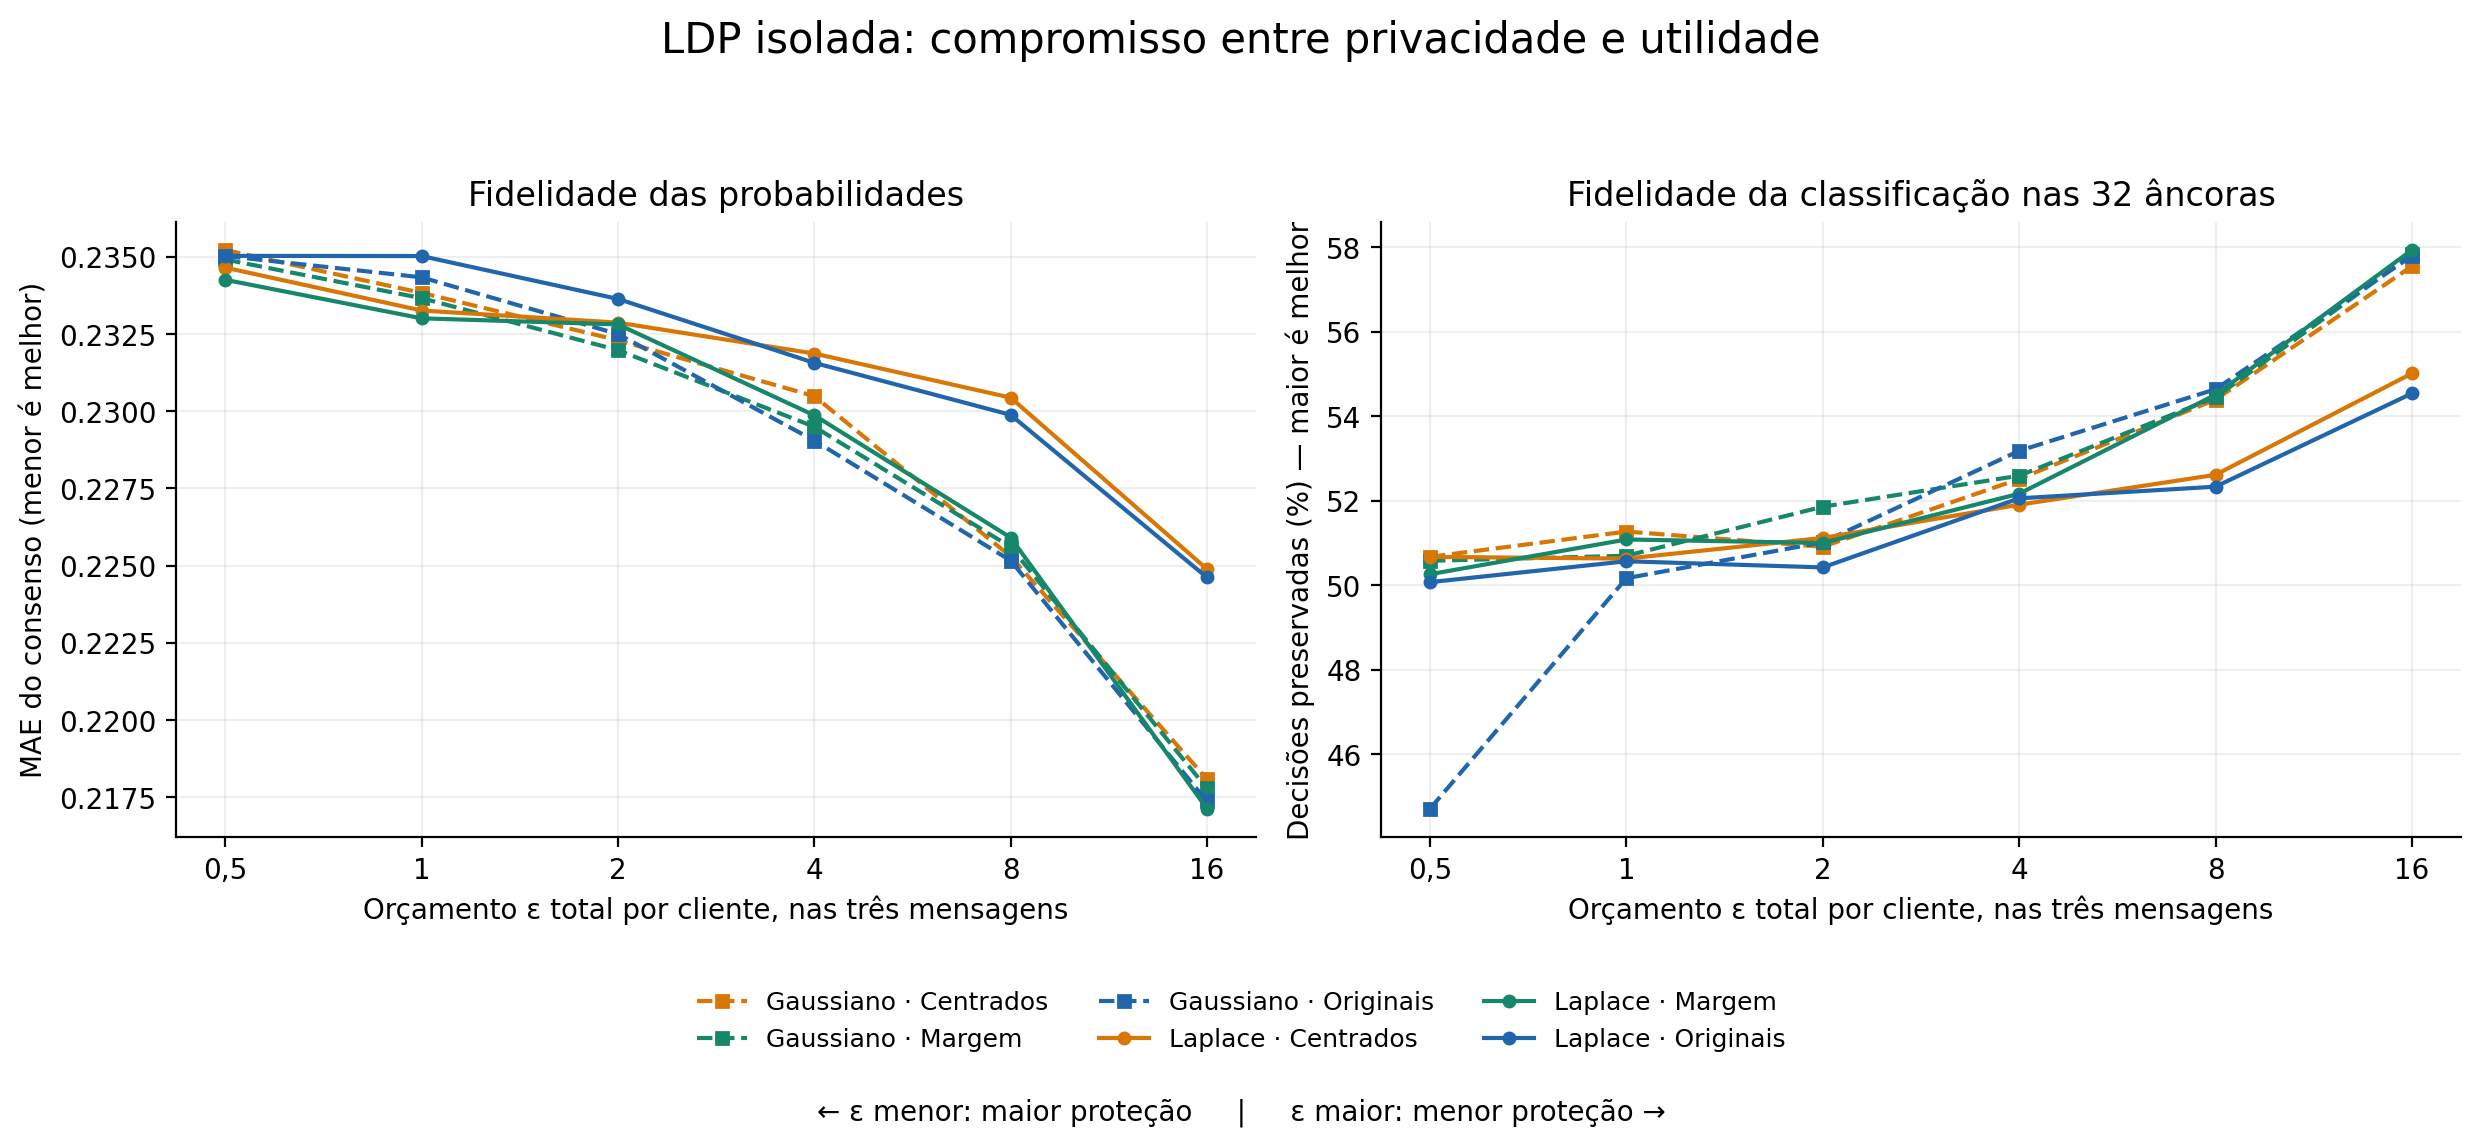

**Como ler:** à esquerda, menor erro é melhor; à direita, maior preservação é melhor. As decisões são comparadas com o consenso original, não com rótulos clínicos. As escalas verticais mostram a variação observada e não começam necessariamente em zero. Sem proteção, a referência seria MAE=0 e preservação=100%. Laplace usa δ=0 e Gaussiano δ total=10⁻⁵; o mesmo ε não iguala as duas garantias. Não estão incluídos resultados de treino FL, SA ou PR-AUC clínico.

In [1]:
from support.ldp_logits.offline_notebooks import render_summary
render_summary()

## 2. Dados e estudo completo

## LDP aplicada apenas aos logits — sem estrutura FL

Este estudo lê mensagens já guardadas e aplica clipping e ruído retrospectivamente. **Não treina modelos locais/globais, não redistribui modelos e não altera o treino FL em execução.** A referência é a configuração A/seed 2031, três ficheiros de rondas históricas, 22 clientes × 32 âncoras × duas classes.

dataset,clientes,peso
icentia11k,16,0.727273
physionet2017,6,0.272727


### Desenho

504 configurações: Laplace/Gaussiano × logits originais/centrados/margem binária × seis epsilons totais (0,5; 1; 2; 4; 8; 16) × 14 limites C. São 200 sorteios por configuração e ronda. Cada cliente é recortado como um vetor conjunto: L1 para Laplace e L2 para Gaussiano, sensibilidade de substituição 2C. Os orçamentos são divididos pelas três mensagens; delta total Gaussiano 10⁻⁵, Laplace zero. Usa-se aleatoriedade reproduzível **apenas para simulação**, não para uma implantação de privacidade.

epsilon_total,mechanism,representation,clip_C,delta_total,consensus_mae_mean,decision_flips_mean,clip_fraction_mean
0.5,laplace,margem,0.25,0.00000,0.234255,15.916667,1.000000
1.0,laplace,margem,0.50,0.00000,0.233008,15.653333,1.000000
2.0,gaussiano,margem,0.25,0.00001,0.231977,15.405000,1.000000
4.0,gaussiano,original,0.50,0.00001,0.229047,14.981667,1.000000
8.0,gaussiano,original,1.00,0.00001,0.225162,14.515000,0.984848
16.0,laplace,margem,32.00,0.00000,0.217127,13.460000,0.984848


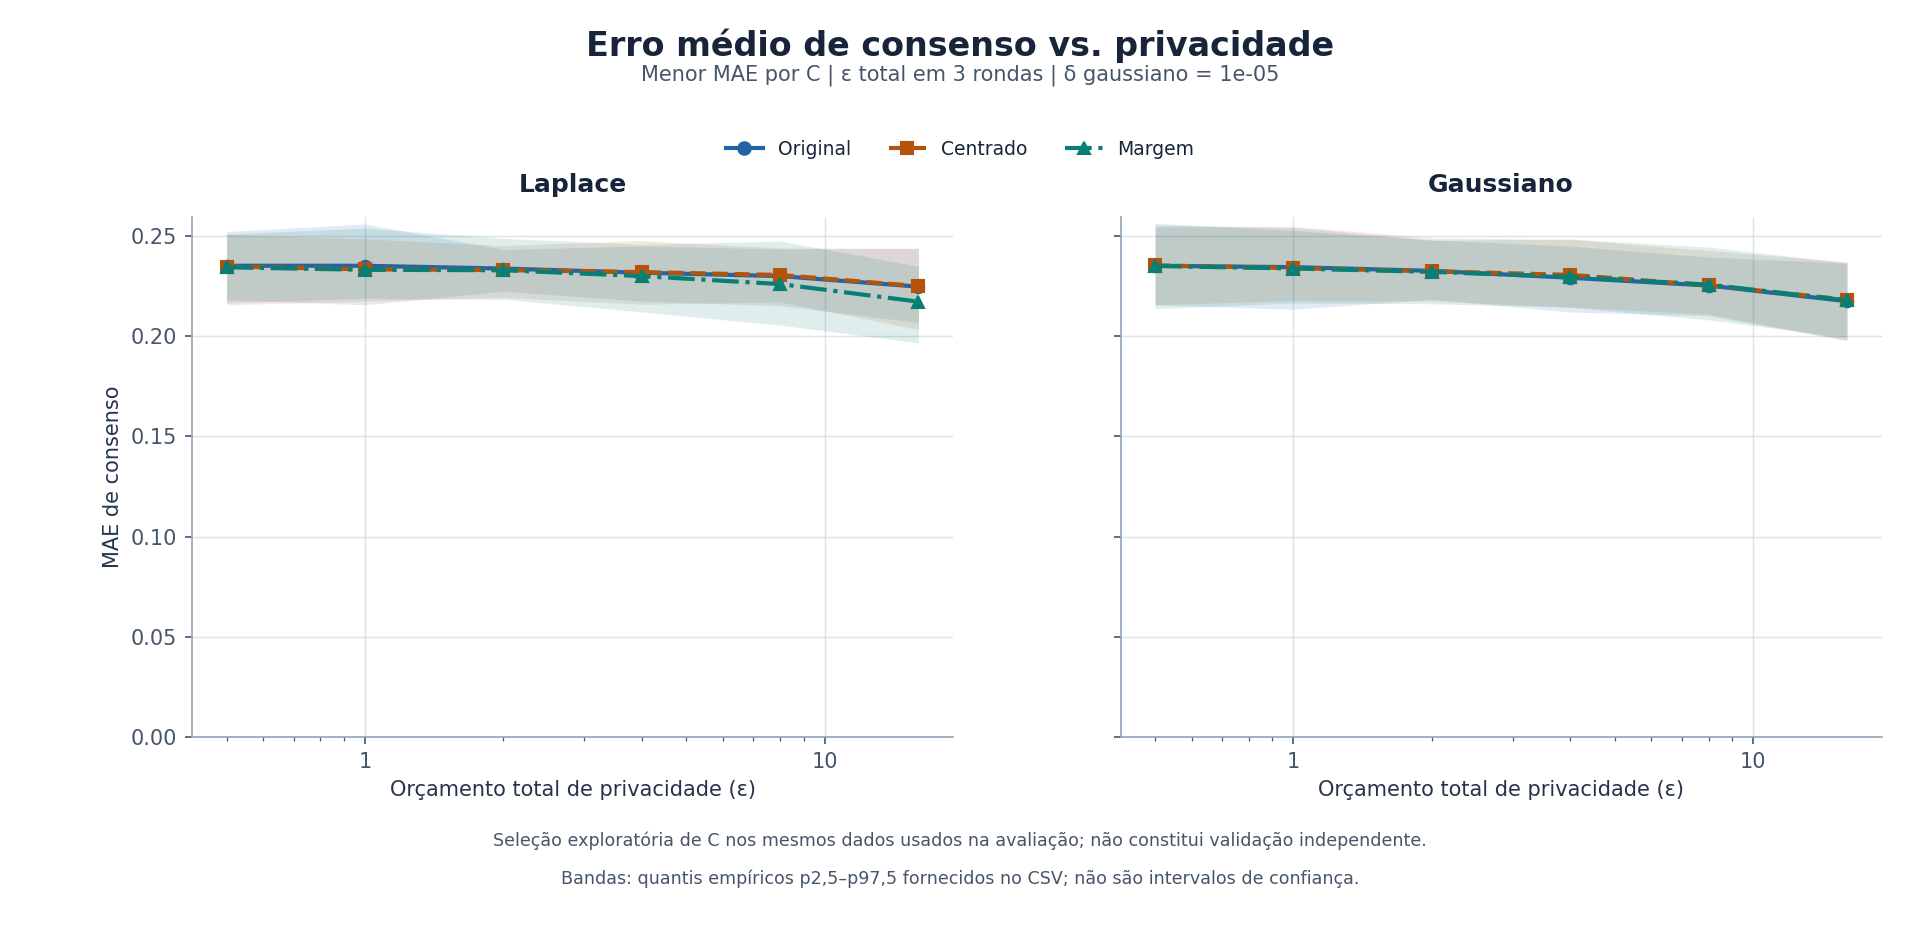

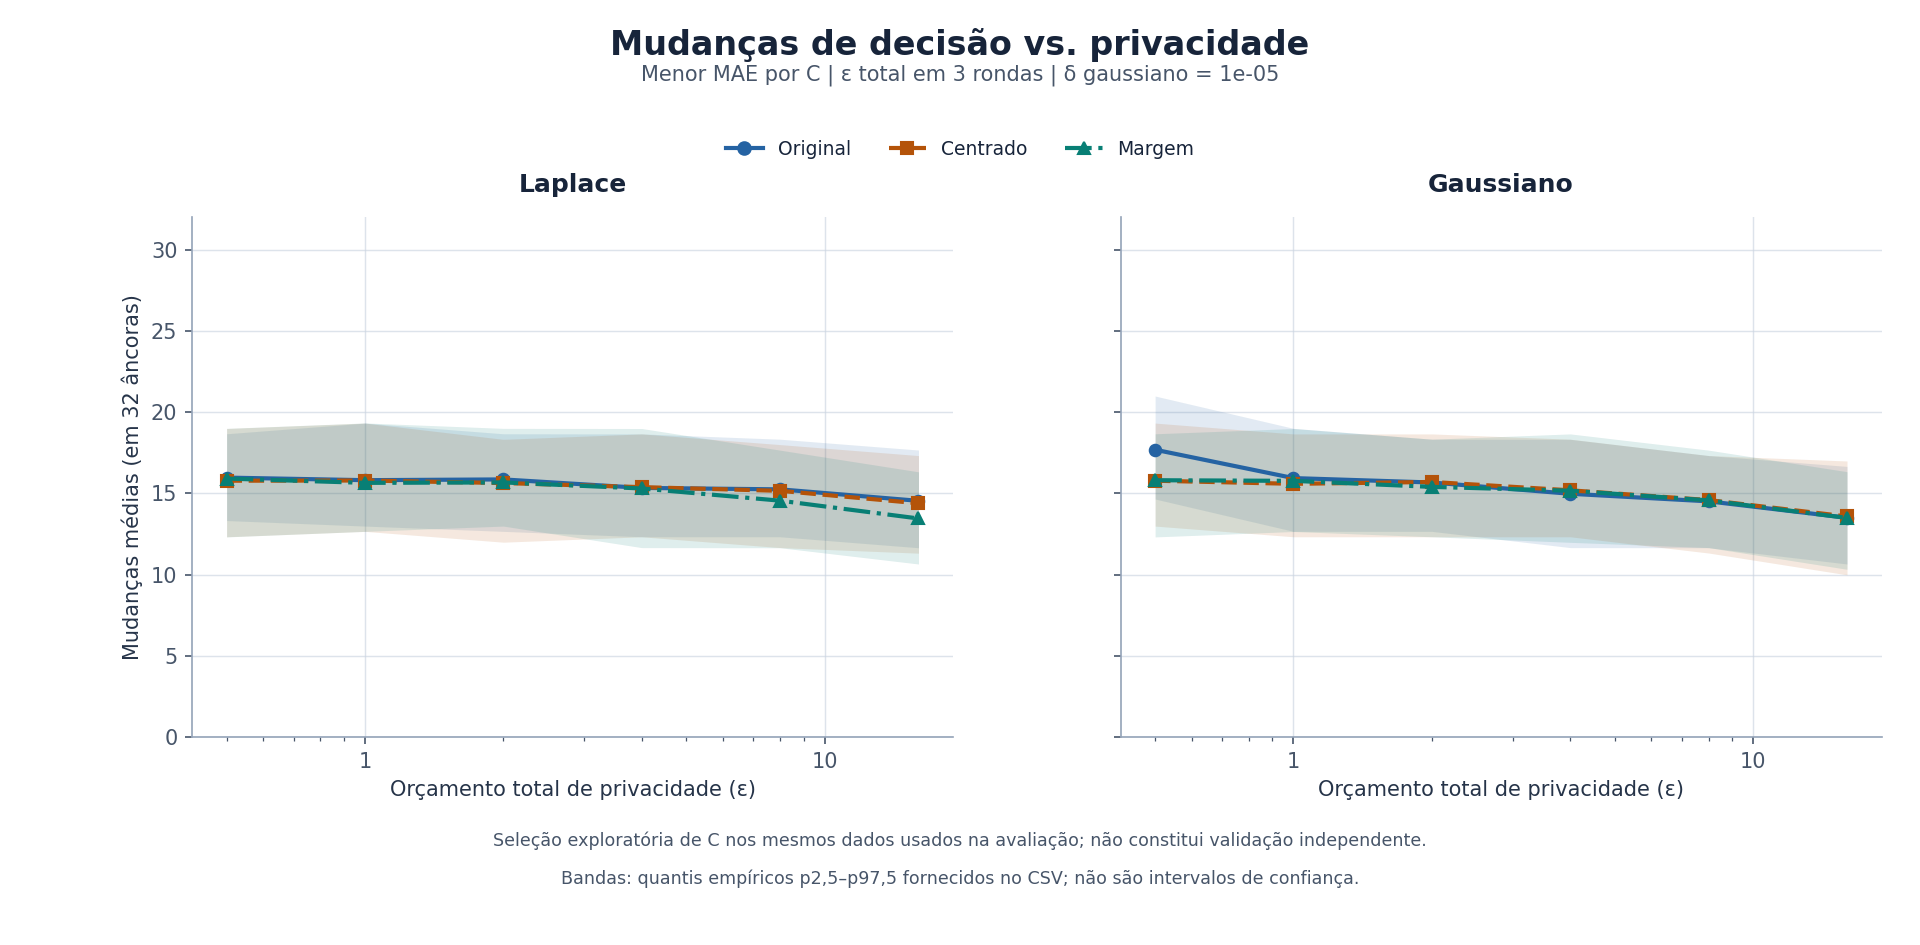

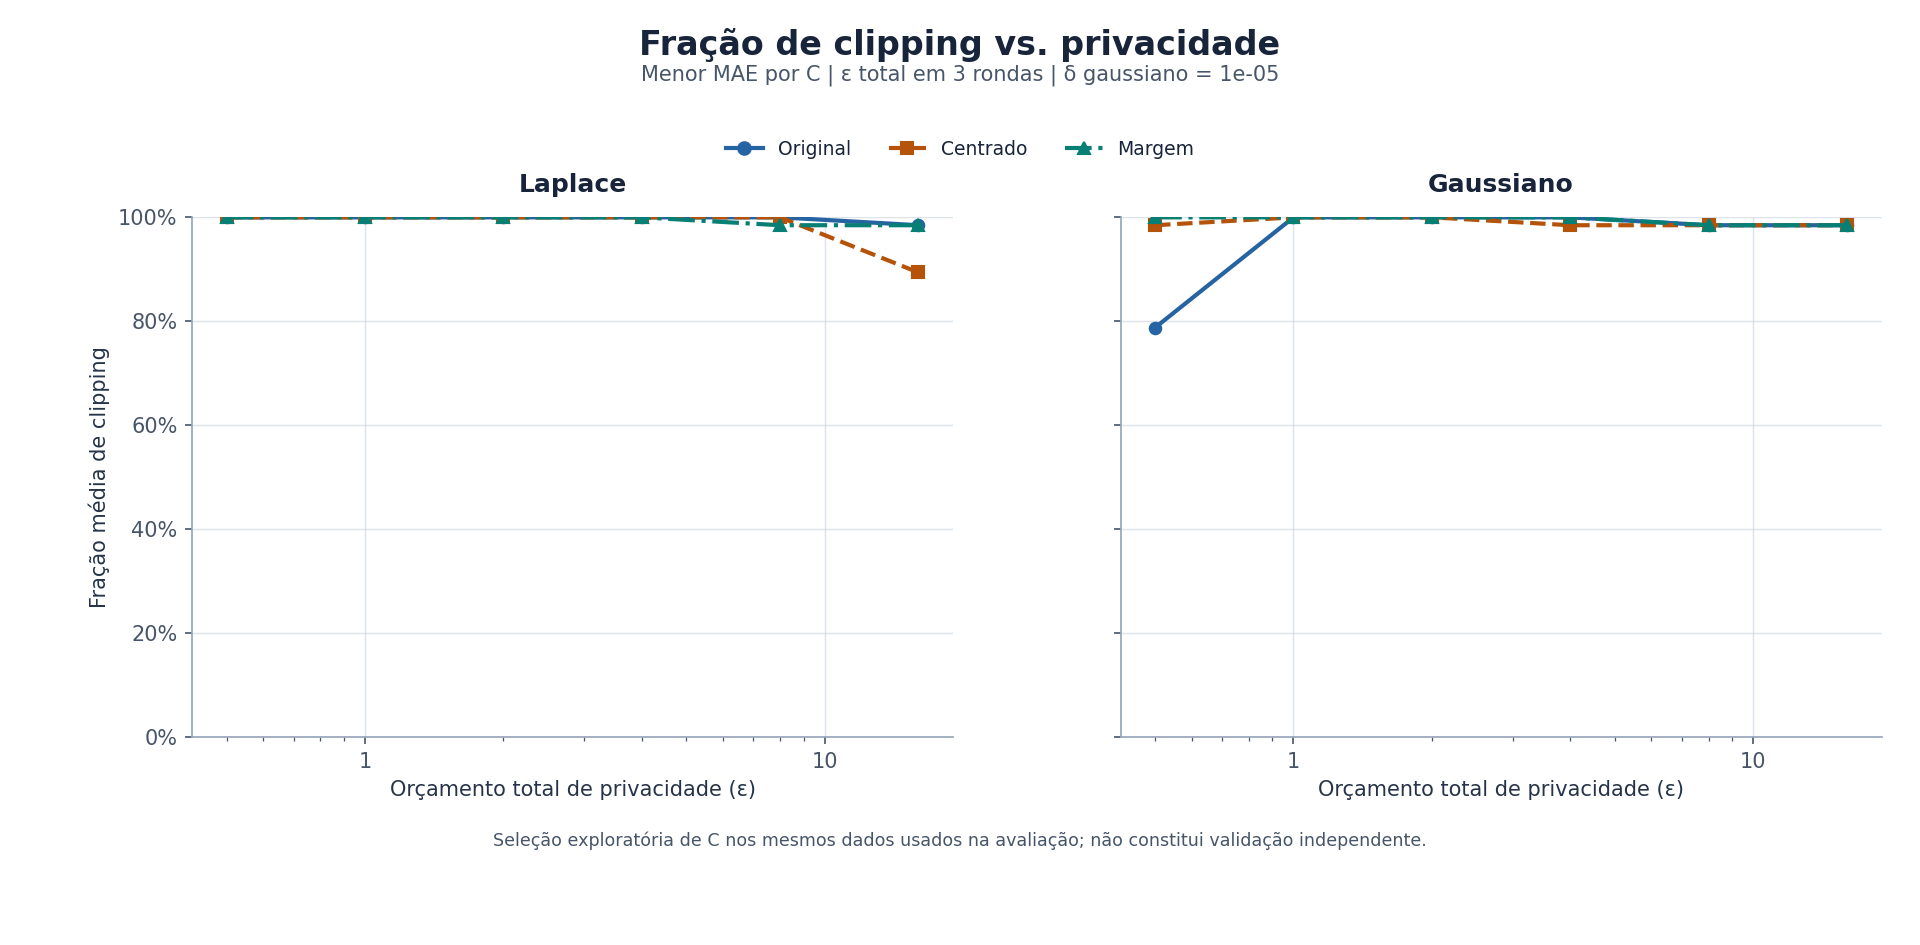

### Métricas deste estudo

MAE/MSE do consenso e das probabilidades, alterações de decisões nas âncoras e fração afetada pelo clipping. **Estas discordâncias não são recall, FAR ou erros clínicos**, pois as âncoras não têm rótulos clínicos. O efeito no PR-AUC de modelos treinados pertence à pasta irmã **LDP + soft labels**, onde o treino continua. Aplicar ruído às rondas congeladas não recria o feedback que haveria num treino privado.

In [1]:
from support.ldp_logits.offline_notebooks import render_experiments
render_experiments()

## 3. Verificação curta e curvas com perfis fixos

## Smoke test: compromisso privacidade–utilidade nos logits

Estudo exploratório sem treino nem arquitetura FL: três mensagens históricas, três perfis fixos, seis valores de ε total e 20 sorteios por perfil, ε e mensagem. Os pesos são verificados: 16/22 Icentia (72,73%) e 6/22 PhysioNet (27,27%).

**Privacidade:** ε menor corresponde a proteção mais forte, para o mesmo mecanismo e δ. O orçamento por cliente é dividido pelas três mensagens. Laplace usa δ=0; Gaussiano usa δ total=10⁻⁵, pelo que não se devem equiparar os mecanismos apenas pelo ε. **Utilidade:** fidelidade ao consenso original, medida por MAE e percentagem de decisões preservadas; não é desempenho clínico.

### Referências para interpretar a perda de utilidade

Sem ruído e sem clipping: MAE=0 e decisões preservadas=100% por definição. A tabela seguinte usa **apenas clipping**, sem garantia LDP, para separar a distorção do clipping da do ruído.

perfil,MAE_consenso,decisoes_preservadas_pct,clientes_com_clipping_pct
gaussiano / margem / C=0.5,0.223822,100.0,100.0
gaussiano / original / C=0.5,0.219492,100.0,100.0
laplace / margem / C=2,0.226257,100.0,100.0


### Resultados com LDP simulado

Médias sobre três mensagens históricas e 20 sorteios por mensagem. O desvio descreve variabilidade de simulação nestes ficheiros, não incerteza de generalização clínica.

perfil,epsilon_total,MAE_consenso,MAE_desvio_simulacao,decisoes_preservadas_pct
gaussiano / margem / C=0.5,0.5,0.233717,0.039406,50.416667
gaussiano / margem / C=0.5,1.0,0.234044,0.042080,51.614583
gaussiano / margem / C=0.5,2.0,0.232998,0.038875,51.927083
gaussiano / margem / C=0.5,4.0,0.225415,0.041658,55.208333
gaussiano / margem / C=0.5,8.0,0.228488,0.042082,54.739583
gaussiano / margem / C=0.5,16.0,0.225827,0.039531,58.072917
gaussiano / original / C=0.5,0.5,0.236390,0.036590,49.583333
gaussiano / original / C=0.5,1.0,0.235098,0.040647,49.635417
gaussiano / original / C=0.5,2.0,0.234573,0.040538,50.937500
gaussiano / original / C=0.5,4.0,0.230134,0.042138,53.229167


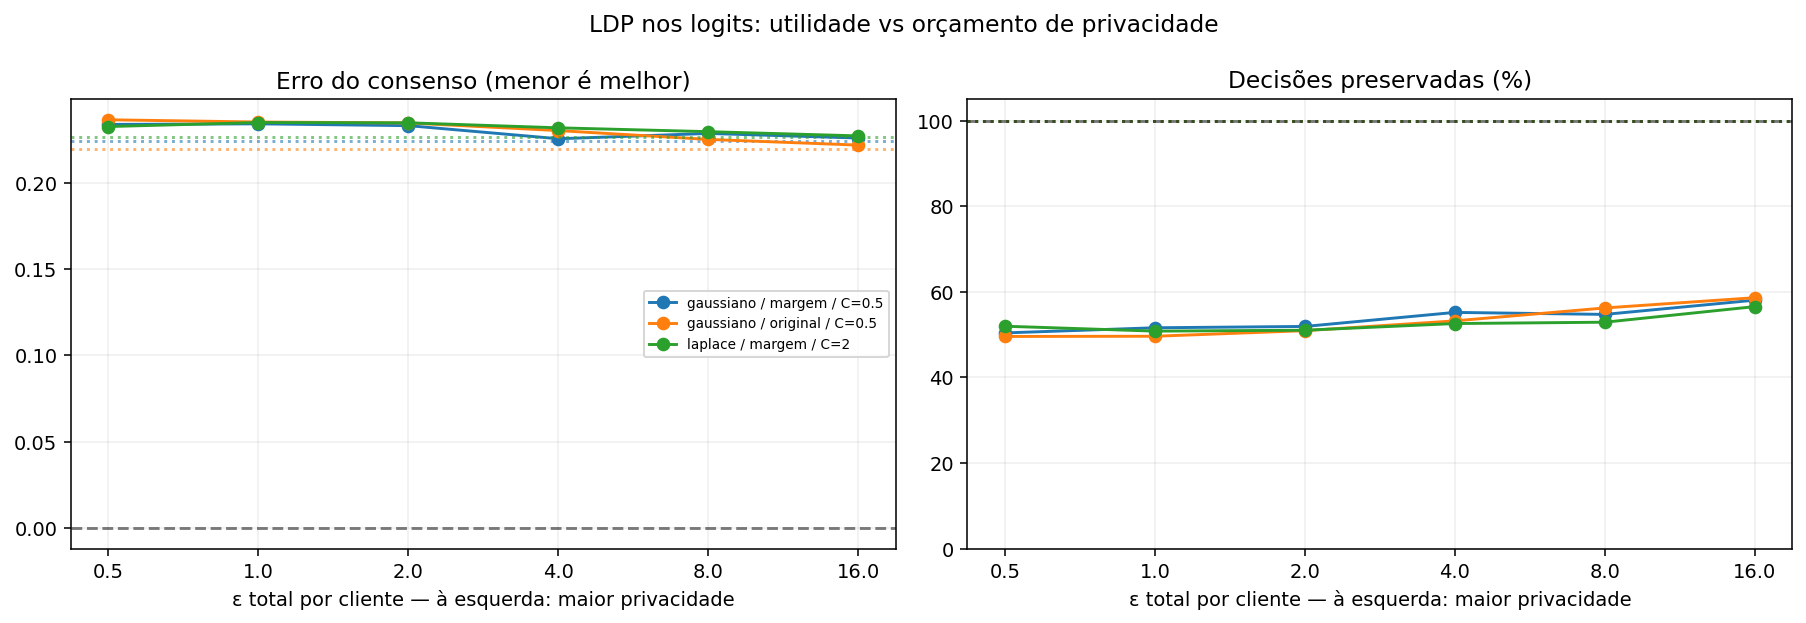

Linhas pontilhadas: controlo só com clipping; linha preta tracejada: referência original sem proteção. Compare os valores de ε **dentro de cada perfil**, mantendo C e representação fixos. Maior ε permite menor ruído, mas clipping pode limitar a recuperação da utilidade; flutuações não monotónicas são possíveis neste smoke test pequeno.

**PASSOU:** pesos, consensos e probabilidades validados. Este teste permite observar o compromisso entre proteção da mensagem e fidelidade ao consenso; não determina sozinho o melhor ε para uso clínico. PR-AUC, recall e FAR exigem dados com rótulos e avaliação dos modelos. O RNG reproduzível é apenas de simulação; ε não contabiliza a divulgação de toda a grelha. Os logits já guardados não ficam protegidos retroativamente.

In [1]:
from support.ldp_logits.smoke import render_smoke
render_smoke()

## 4. Comparação e interpretação

## Comparação isolada privacidade–fidelidade dos logits

**Peso atual: 72,73% Icentia11k e 27,27% PhysioNet.** Menor epsilon representa proteção mais exigente do mecanismo e, em geral, maior ruído. Não se deve escolher o maior epsilon apenas por apresentar menor erro. Laplace e Gaussiano têm delta diferente.

epsilon_total,mechanism,representation,clip_C,delta_total,consensus_mae_mean,consensus_mse_mean,decision_flips_mean
0.5,laplace,margem,0.25,0.00000,0.234255,0.065270,15.916667
0.5,laplace,centrado,0.50,0.00000,0.234650,0.068094,15.785000
0.5,gaussiano,margem,0.25,0.00001,0.234912,0.067976,15.815000
1.0,laplace,margem,0.50,0.00000,0.233008,0.064480,15.653333
1.0,laplace,centrado,0.25,0.00000,0.233260,0.064080,15.798333
1.0,gaussiano,margem,0.25,0.00001,0.233661,0.066453,15.776667
2.0,gaussiano,margem,0.25,0.00001,0.231977,0.063757,15.405000
2.0,gaussiano,centrado,0.25,0.00001,0.232299,0.064997,15.708333
2.0,gaussiano,original,0.25,0.00001,0.232498,0.065046,15.675000
4.0,gaussiano,original,0.50,0.00001,0.229047,0.063678,14.981667


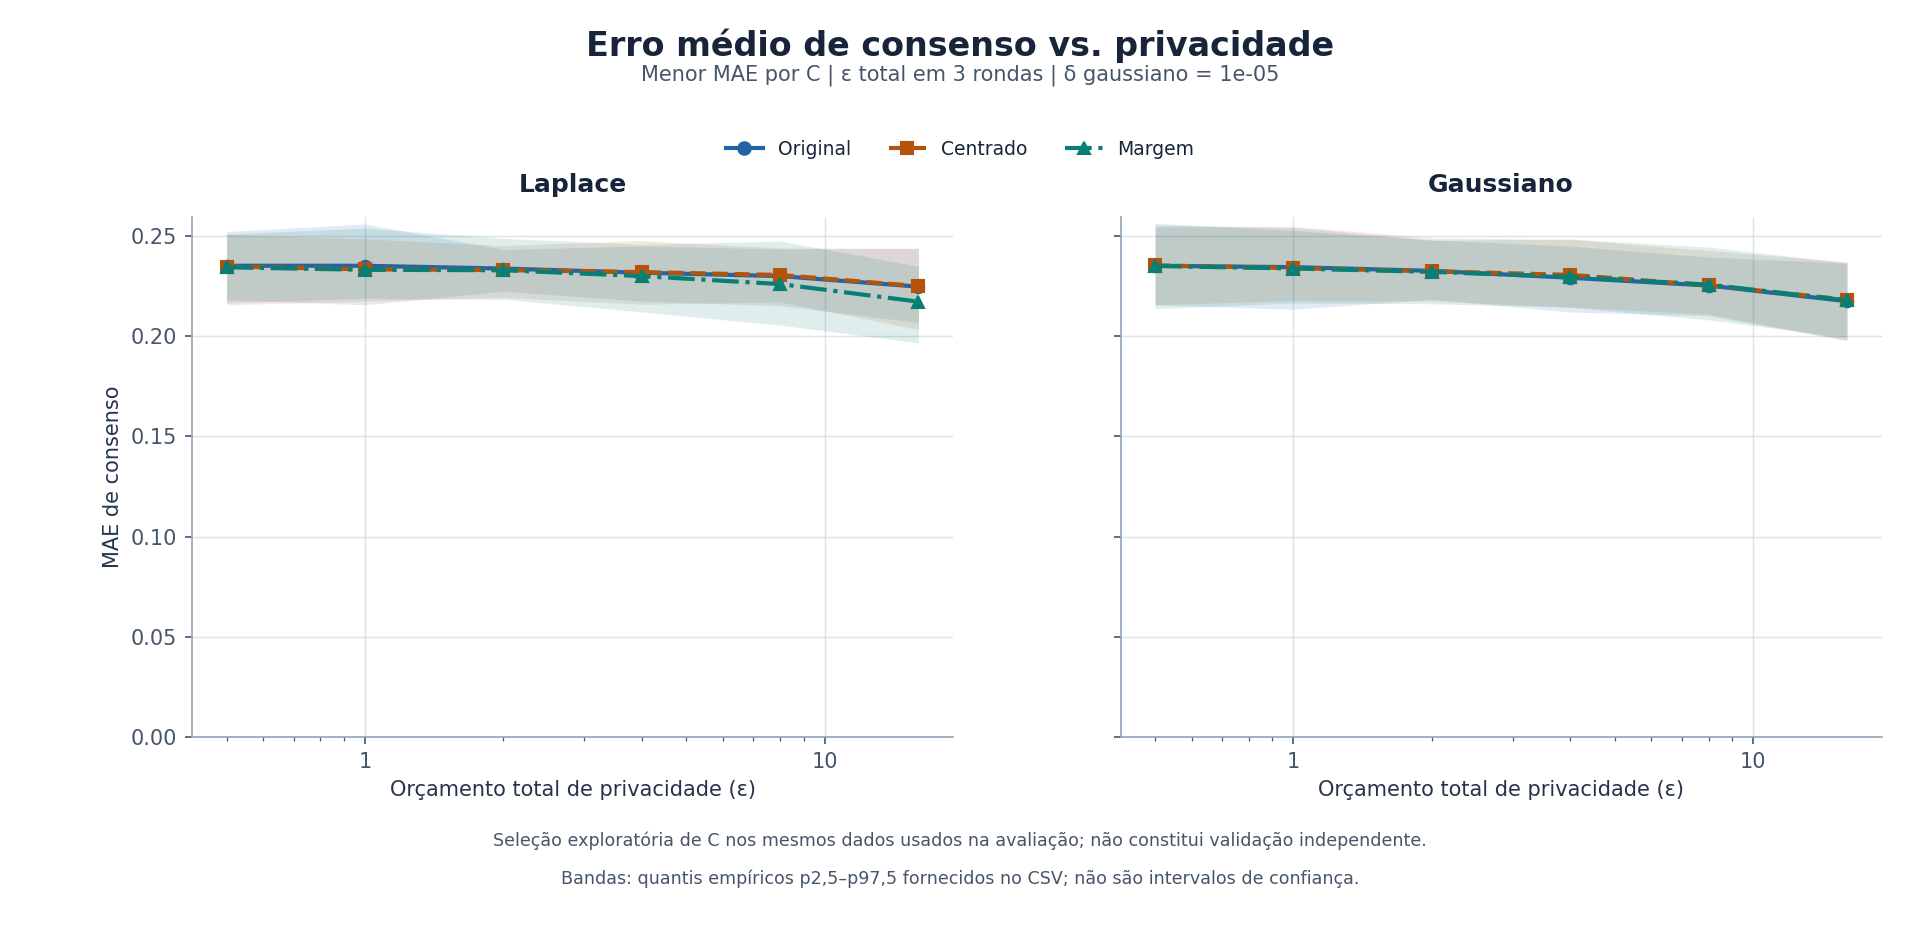

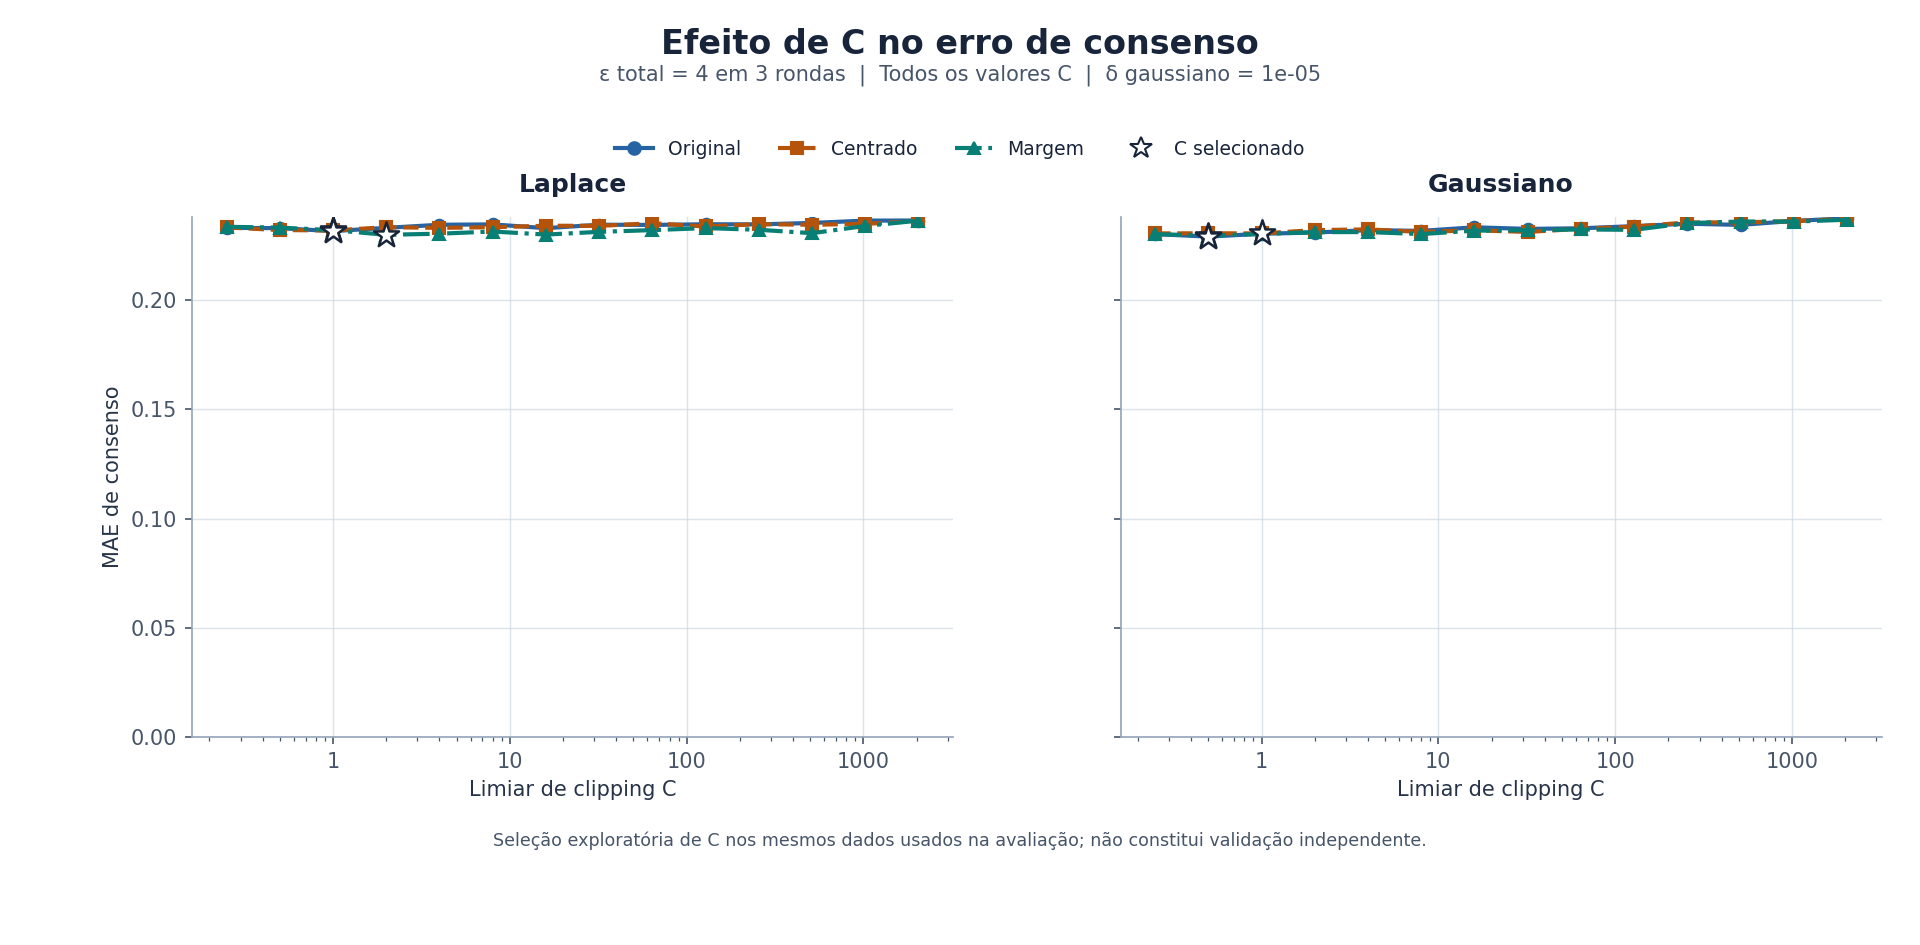

### Opções com epsilon total = 4

Estas três opções foram selecionadas exploratoriamente pelo MAE nos mesmos logits; não constituem prova de superioridade nem escolha protegida por DP.

mechanism,representation,clip_C,delta_total,consensus_mae_mean,consensus_mae_se_mean,decision_flips_mean
gaussiano,original,0.5,0.00001,0.229047,0.000600,14.981667
gaussiano,margem,0.5,0.00001,0.229495,0.000577,15.170000
laplace,margem,2.0,0.00000,0.229867,0.000611,15.306667


mechanism,representation,clip_C,MAE_so_clipping,MAE_clipping_e_ruido,fracao_clipping
gaussiano,original,0.5,0.219492,0.229047,1.0
gaussiano,margem,0.5,0.223822,0.229495,1.0
laplace,margem,2.0,0.226257,0.229867,1.0


O controlo só com clipping não é privado. Não se somam diretamente os erros de clipping e ruído depois da softmax. Os quantis e erros-padrão descrevem a aleatoriedade de simulação nos mesmos logits, não generalização clínica.

**Âmbito:** a proteção estudada é da mensagem conjunta preparada de um cliente sob parâmetros e transformações fixos. Normalização histórica, participação, seleção de C, métricas e divulgação dos logits originais exigem análise separada. Este estudo não protege retrospectivamente dados já publicados e não é uma execução FL nem uma divulgação DP de todo o sistema.

In [1]:
from support.ldp_logits.offline_notebooks import render_comparison
render_comparison()